# 01. TabPFN-3.5가 바꾼 것과 multitask 구조

TabPFN-3.5(Prior Labs, *TabPFN-3.5: Technical Report*, arXiv 2609.17895, 2026)는 TabPFN-3의 열 → 행 → 행 ICL 뼈대를 그대로 두고, 폭을 넓히고 셀 encoder를 바꾸고 분류와 회귀를 checkpoint 하나로 합쳤습니다. 3의 구조는 [05_tabpfn_v3/01 한눈에 보기와 셀 encoder](../05_tabpfn_v3/01_overview_and_cell_encoder.ipynb)와 [05_tabpfn_v3/02 열 → 행 → 행 ICL 세 단계](../05_tabpfn_v3/02_column_row_icl_stages.ipynb)에서 다뤘으니, 여기서는 바뀐 부분만 봅니다. v1부터 3.5까지의 차이는 [노트북 로드맵의 버전 비교 표](../README.md#tabpfn-버전-비교)에 모았고, 이 노트북은 그 표의 3 → 3.5 칸을 따라갑니다.

코드는 3과 같은 `src/minipfn/models/column_row_transformer.py`(`ColumnRowTransformer`)이고 설정만 다릅니다(`src/minipfn/recipes/tabpfn_v3.py`의 `ARCHITECTURES`). 마지막으로 분류와 회귀를 모델 하나가 하는 multitask 구조를 과일 표로 따라갑니다.

다루는 흐름:

1. 한눈에 보기 — 바뀐 설정과 파라미터 수
2. 셀 encoder: Linear → Fourier + ECDF
3. 나머지 셋 — `qk_norm`, `target_norm`, `head_mlp`
4. 분류·회귀를 한 모델로 (`multitask`)
5. 정리

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다. 이 노트북은 `notebooks/06_tabpfn_v3_5/` 아래에 있으므로 저장소 루트는 두 단계 위입니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch import nn

from minipfn import set_seed
from minipfn.models import randomize_zero_weights
from minipfn.models.column_row_transformer import (
    ColumnRowTransformer,
    ColumnRowTransformerConfig,
    FourierCellEncoder,
    TargetEncoder,
    ecdf_midrank,
)
from minipfn.recipes.tabpfn_v3 import ARCHITECTURES, paper

set_seed(0)  # 재현성을 위해 난수 시드를 고정한다.

## 1. 한눈에 보기 — 바뀐 설정과 파라미터 수

3.5 보고서는 세 단계 뼈대를 그대로 두고 아래를 바꿨습니다. 셀 묶기(feature $j$의 토큰에 열 $j$, $j+1$, $j+3$의 셀)와 학습 행의 셀 토큰마다 정답 embedding을 더하는 방식은 3과 같습니다([05_tabpfn_v3/01 3절](../05_tabpfn_v3/01_overview_and_cell_encoder.ipynb)). 보고서에 없는 것(정답 LayerNorm, 출력층 앞 MLP)은 공개 추론 코드에서 확인했습니다. `ARCHITECTURES`에서 3과 3.5의 분류 설정 중 다른 것만 뽑습니다.

In [3]:
v3, v35 = ARCHITECTURES["v3"]["classification"], ARCHITECTURES["v3.5"]["classification"]
changed = {name: {"v3": v3[name], "v3.5": v35[name]} for name in v3 if v3[name] != v35[name]}
meaning = {
    "n_cls": "CLS 수 (행 벡터 폭 = n_cls × 128)",
    "nhead": "행 ICL head 수 (head dim 64 그대로)",
    "qk_norm": "attention의 q·k에 RMSNorm",
    "encoder": "셀 encoder (2절)",
    "target_norm": "정답 embedding 뒤 LayerNorm",
    "head_mlp": "출력층 앞 task별 잔차 MLP",
}
display(pd.DataFrame(changed).T.assign(뜻=lambda t: t.index.map(meaning)))

,v3,v3.5,뜻
nhead,8,16,행 ICL head 수 (head dim 64 그대로)
n_cls,4,8,CLS 수 (행 벡터 폭 = n_cls × 128)
qk_norm,False,True,attention의 q·k에 RMSNorm
encoder,linear,fourier,셀 encoder (2절)
target_norm,False,True,정답 embedding 뒤 LayerNorm
head_mlp,False,True,출력층 앞 task별 잔차 MLP


실제 크기의 모델을 만들어 파라미터를 단계별로 셉니다. 05 노트북과 같이 모델의 맨 앞 이름(`column_blocks`, `icl_layers` 등)을 단계로 묶고, 3 분류 모델과 나란히 놓습니다. 3.5 multitask 모델(2억 개 남짓)은 한 번만 만들어, 4절에서 쓸 task별 파라미터 수도 여기서 같이 셉니다.

In [4]:
# 모델이 단계마다 센 파라미터 수(`num_parameters_by_stage`)에 붙일 이름
STAGE_LABEL = {
    "cell_encoder": "셀 encoder",
    "column_stage": "열 단계",
    "row_stage": "행 단계",
    "row_icl": "행 ICL",
    "output": "출력",
}


def stage_counts(model):
    counts = {STAGE_LABEL[k]: v for k, v in model.num_parameters_by_stage().items()}
    counts["합계"] = model.num_parameters()
    return counts


counts = {}
for arch, task in [("v3", "classification"), ("v3.5", "multitask")]:
    model = paper(task, arch).build_model()
    counts[f"{arch} {task}"] = stage_counts(model)
    if task == "multitask":
        # 219M 모델을 4절에서 다시 만들지 않도록 여기서 센다
        full_split = model.num_parameters_by_task()
    del model

order = ["셀 encoder", "열 단계", "행 단계", "행 ICL", "출력", "합계"]
param_table = pd.DataFrame(counts).reindex(order).fillna(0).astype(int)
display(param_table.style.format("{:,}"))

,v3 classification,v3.5 multitask
셀 encoder,"2,176","30,752"
열 단계,"869,616","869,808"
행 단계,"394,624","395,232"
행 ICL,"51,363,328","203,194,368"
출력,"427,392","14,336,264"
합계,"53,057,136","218,826,424"


파라미터가 4배로 는 것은 거의 다 둘째 줄(`n_cls`) 때문입니다. 첫 줄의 head 수는 head 폭을 64로 두고 폭을 나누는 개수만 바꾸므로 파라미터 수와는 상관이 거의 없습니다. CLS가 4개에서 8개가 되어 행 벡터 폭이 512에서 1,024로 두 배가 되면, 행 ICL 층의 파라미터는 폭의 제곱에 비례하니 네 배가 됩니다(위 표의 행 ICL 5,136만 → 2억 319만). 3.5 보고서는 층 수를 적지 않아서 3의 24층을 그대로 두었고, 그러면 전체가 2억 1,883만 개로 보고서의 "220M"과 비슷해집니다. 3.5 multitask 모델은 분류와 회귀의 출력층을 둘 다 갖고 있어서 출력 쪽도 큽니다.

## 2. 셀 encoder: Linear → Fourier + ECDF

먼저 그대로인 것입니다. 3.5도 feature $j$의 토큰에 열 $j$, $j+1$, $j+3$의 셀을 넣어 칸 3개를 만듭니다([05_tabpfn_v3/01 3절 2단계](../05_tabpfn_v3/01_overview_and_cell_encoder.ipynb)). 그래서 토큰 수는 feature 수와 같고, 0으로 채우는 칸도 없습니다. 바뀐 것은 이 칸 3개를 E차원 벡터 하나로 바꾸는 encoder입니다.

3은 칸마다 [z값, 결측 표시] 두 숫자를 꺼내, 토큰 하나에 숫자 6개를 Linear 하나에 넣었습니다. 3.5는 칸마다 숫자를 더 많이 만들어 두 갈래로 나눠 Linear하고, 두 결과를 더한 뒤 LayerNorm합니다.

- **Fourier 갈래**: 칸의 z값에 학습되는 주파수 32개를 곱해 sin·cos을 만듭니다. 주파수의 처음 값(0.1~10, log 간격)은 이 저장소가 정했습니다.
- **메타 갈래**: 칸마다 z값, 결측 표시, 그리고 열 안에서 그 값의 순위로 만든 sin·cos 8개(아래에서 손 계산)를 둡니다.

칸 하나와 토큰 하나(칸 3개)에서 encoder에 들어가는 숫자 개수를 실제 encoder로 셉니다.

In [5]:
linear_check = nn.Linear(2 * 3, 128)  # 3: 칸 3개 × [z값, 결측 표시]
fourier_check = FourierCellEncoder(3, 128)  # 3.5: 칸 3개, E = 128
widths = {
    "3: Linear": linear_check.in_features,
    "3.5: Fourier 갈래": fourier_check.fourier.in_features,
    "3.5: 메타 갈래": fourier_check.metadata.in_features,
}
print("encoder에 들어가는 숫자 개수")
display(
    pd.DataFrame(
        {"칸 하나": {k: v // 3 for k, v in widths.items()}, "토큰 하나 (칸 3개)": widths}
    )
)

encoder에 들어가는 숫자 개수


,칸 하나,토큰 하나 (칸 3개)
3: Linear,2,6
3.5: Fourier 갈래,64,192
3.5: 메타 갈래,10,30


3은 칸마다 2개였지만, 3.5는 Fourier 갈래에서 64개(주파수 32개 × sin·cos), 메타 갈래에서 10개(z값, 결측 표시, 순위 sin·cos 8개)를 만듭니다.

메타 갈래의 순위를 무게 열로 손 계산합니다. 학습 행의 무게는 190g, 210g, 290g, 320g입니다. 테스트 5(200g)는 190g보다 무겁고 210g보다 가벼우니, 학습 값 넷 가운데 아래에서 4분의 1쯤 되는 자리입니다. 이 자리를 0~1의 숫자 $u$로 나타낸 것이 순위이고, 정확히는 학습 행에 대한 midrank입니다.

$$u = \frac{\text{나보다 작은 학습 값 수} + \text{나와 같은 학습 값 수} / 2}{\text{학습 행 수}}$$

메타 갈래의 순위 항은 이 $u$로 만든 $\sin(\pi k u)$, $\cos(\pi k u)$($k = 1, 2, 3, 4$) 8개입니다.

In [6]:
fruit = pd.DataFrame(
    {
        "무게(g)": [210, 190, 320, 290, 200, 310],
        "당도(brix)": [13.5, 14.0, 11.0, 11.5, 13.0, 12.0],
        "지름(cm)": [7.5, 7.2, 9.0, 8.6, 7.4, 8.8],
        "산도(pH)": [3.4, 3.5, 3.9, 3.8, 3.4, 3.9],
        "껍질(mm)": [0.6, 0.5, 1.0, 0.9, 0.6, 1.0],
    }
)
y = np.array([0, 0, 1, 1])  # 학습 행의 정답: 0 = 사과, 1 = 배
n_train = 4
roles = ["학습 1", "학습 2", "학습 3", "학습 4", "테스트 5", "테스트 6"]

features = fruit.to_numpy(dtype=float)
mean = features[:n_train].mean(axis=0)
std = features[:n_train].std(axis=0)  # 모델과 같이 n으로 나눈 표준편차
z = (features - mean) / std
grams = features[:, 0]  # 무게 열

In [7]:
train_grams = np.sort(grams[:n_train])
midrank_rows = {}
for i, role in enumerate(roles):
    smaller = int((train_grams < grams[i]).sum())
    equal = int((train_grams == grams[i]).sum())
    midrank_rows[role] = {
        "무게(g)": grams[i],
        "작은 수": smaller,
        "같은 수": equal,
        "u (손 계산)": (smaller + equal / 2) / n_train,
    }
midrank_table = pd.DataFrame(midrank_rows).T

u_model = ecdf_midrank(torch.tensor(features, dtype=torch.float32)[None], n_train)[0, :, 0]
midrank_table["u (모델)"] = u_model.numpy()
display(midrank_table.round(3))

,무게(g),작은 수,같은 수,u (손 계산),u (모델)
학습 1,210.0,1.0,1.0,0.375,0.375
학습 2,190.0,0.0,1.0,0.125,0.125
학습 3,320.0,3.0,1.0,0.875,0.875
학습 4,290.0,2.0,1.0,0.625,0.625
테스트 5,200.0,1.0,0.0,0.250,0.250
테스트 6,310.0,3.0,0.0,0.750,0.750


학습 1(210g)은 자기보다 작은 학습 값이 1개, 같은 값이 1개(자기 자신)라 $u = (1 + 0.5)/4 = 0.375$입니다. 테스트 5(200g)는 190g과 210g 사이라 작은 값 1개, 같은 값 0개로 $u = 0.25$입니다. 모델의 `ecdf_midrank`도 같은 값을 냅니다.

z값은 평균과 표준편차로만 정규화하므로 값 하나가 아주 크면(이상치) 나머지가 좁은 곳에 몰립니다. 순위 $u$는 이상치가 있어도 늘 0~1에 고르게 퍼집니다. 3까지는 추론 때 quantile 변환한 앙상블 멤버를 따로 만들어 비슷한 효과를 냈습니다. 3.5는 추론 전처리에서 quantile·robust·SVD를 빼고 standard 하나만 쓰는데(`INFERENCE["v3.5"]`), encoder가 순위를 직접 보게 된 것과 맞물린 변화로 보입니다.

Fourier 항은 값에 따라 꺾이는 표현을 처음부터 만들 수 있게 합니다. 토큰의 칸 1 z값만 $-3$에서 $3$까지 바꾸고 칸 2·3은 0으로 둔 채, 두 encoder가 만드는 토큰의 앞 세 차원을 그립니다. 학습하지 않은 무작위 가중치입니다.

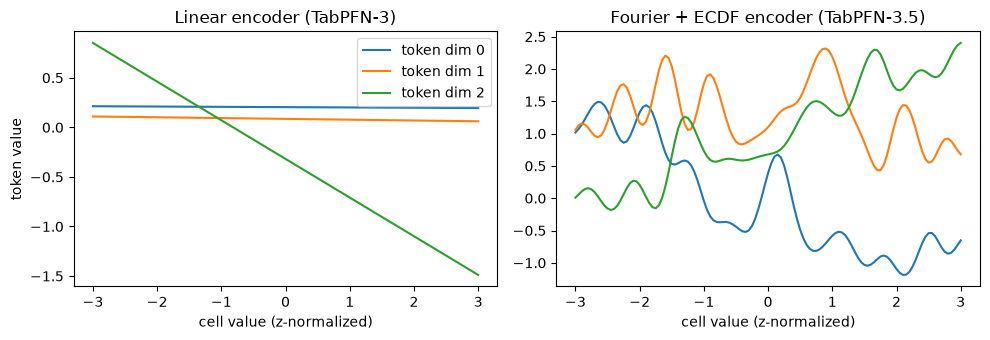

In [8]:
torch.manual_seed(0)
E_small = 16
linear_encoder = nn.Linear(2 * 3, E_small)  # 3: [값 3개, 결측 표시 3개]
fourier_encoder = FourierCellEncoder(3, E_small)  # 3.5

sweep = torch.linspace(-3, 3, 121)
values_in = torch.zeros(len(sweep), 3)
values_in[:, 0] = sweep  # 첫 칸 z값만 바꾼다
indicator_in = torch.zeros(len(sweep), 3)
u_in = torch.full((len(sweep), 3), 0.5)
u_in[:, 0] = torch.distributions.Normal(0, 1).cdf(sweep)  # 정규분포 열이라고 보고 순위를 정한다

with torch.no_grad():
    tokens = {
        "Linear encoder (TabPFN-3)": linear_encoder(torch.cat([values_in, indicator_in], dim=-1)),
        "Fourier + ECDF encoder (TabPFN-3.5)": fourier_encoder(
            values_in[None, None], indicator_in[None, None], u_in[None, None]
        )[0, 0],
    }

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharex=True)
for ax, (title, out) in zip(axes, tokens.items(), strict=True):
    for d in range(3):
        ax.plot(sweep, out[:, d], label=f"token dim {d}")
    ax.set_title(title)
    ax.set_xlabel("cell value (z-normalized)")
axes[0].set_ylabel("token value")
axes[0].legend()
plt.tight_layout()
plt.show()

Linear encoder의 토큰은 셀 값에 대해 직선이라, 값에 따라 꺾이는 표현은 뒤의 층들이 만들어야 합니다. Fourier encoder는 주파수가 다른 sin·cos이 섞여 값에 따라 여러 번 꺾입니다. `FourierCellEncoder` 하나의 파라미터는 2만 9천 개쯤이라 모델 전체에 비하면 아주 작습니다(1절 표의 3.5 '셀 encoder' 30,752개는 여기에 셀 단계 정답 embedding과 그 LayerNorm을 더한 수입니다).

## 3. 나머지 셋 — `qk_norm`, `target_norm`, `head_mlp`

- **`qk_norm`**: attention의 q와 k를 head 차원마다 RMSNorm합니다. q·k의 크기가 묶이니 attention logit이 끝없이 커지지 않습니다. v2 회귀를 학습할 때 logit이 수십만까지 커져 QK-clip으로 상한을 뒀는데, 이 구조에서는 QK-clip이 logit을 묶지 못합니다. QASSMax가 q에 입력에 따라 달라지는 배율을 곱하고, 테스트 행은 다른 head의 key를 보기 때문입니다. 그래서 이 저장소는 3·3.5 모두 QK-clip을 끄고(`with_architecture`), logit을 묶는 일은 3.5의 `qk_norm`에 맡깁니다.
- **`target_norm`**: 정답 embedding을 더하기 전에 LayerNorm합니다(셀 단계·행 ICL 각각). 더하는 곳은 3과 같습니다. 셀 단계에서는 학습 행의 셀 토큰 전부에, 행 ICL에서는 학습 행 벡터에 더하고, 테스트 행에는 더하지 않습니다([05_tabpfn_v3/01 3절 4단계](../05_tabpfn_v3/01_overview_and_cell_encoder.ipynb)). 분류의 클래스 벡터와 회귀의 `Linear(y)`는 크기가 다를 수 있는데, 두 task가 이 LayerNorm을 같이 써서 정답 신호의 크기를 task와 상관없이 맞춥니다.
- **`head_mlp`**: 출력층 앞에 task마다 잔차 MLP 하나를 둡니다. 마지막 층이 0으로 시작해 처음에는 아무것도 하지 않습니다.

`target_norm`이 정답 벡터에 무엇을 하는지 [05_tabpfn_v3/01](../05_tabpfn_v3/01_overview_and_cell_encoder.ipynb) 3절 4단계의 손 계산(E = 4, 회귀 정답은 한 개 가격)으로 봅니다. 분류 정답은 사과·배 클래스 벡터이고, 회귀 정답은 $e(y) = y \cdot w + b$입니다. 같은 LayerNorm 하나를 두 task가 같이 씁니다.

In [9]:
price = np.array([1500, 1300, 2800, 2500])  # 학습 행의 한 개 가격(원), 4절에서도 쓴다
price_z = (price - price.mean()) / price.std()  # 회귀 정답은 학습 행으로 표준화한다

torch.manual_seed(0)
class_target = TargetEncoder("classification", 2, 4)  # 사과·배 벡터 (직교로 시작)
reg_target = TargetEncoder("regression", 1, 4)  # Linear(1 → 4)
target_norm = nn.LayerNorm(4)  # 3.5: 두 task가 같이 쓴다
with torch.no_grad():
    reg_target.encode.weight[:, 0] = torch.tensor([1.0, -0.5, 0.2, 0.0])  # 05_tabpfn_v3/01과 같은 w
    reg_target.encode.bias[:] = torch.tensor([0.1, 0.0, 0.0, 0.3])  # b
    e_class = class_target(torch.tensor(y, dtype=torch.float32)[None], torch.float32)[0]
    e_reg = reg_target(torch.tensor(price_z, dtype=torch.float32)[None], torch.float32)[0]
    n_class, n_reg = target_norm(e_class), target_norm(e_reg)


def vec(t):
    return "[" + ", ".join(f"{v:.2f}" for v in t) + "]"


display(
    pd.DataFrame(
        {
            "분류 정답": ["사과", "사과", "배", "배"],
            "분류 크기 (3)": e_class.norm(dim=-1).numpy().round(2),
            "분류 크기 (3.5)": n_class.norm(dim=-1).numpy().round(2),
            "가격(원)": price,
            "회귀 e(y) (3)": [vec(t) for t in e_reg],
            "회귀 크기 (3)": e_reg.norm(dim=-1).numpy().round(2),
            "LayerNorm(e(y)) (3.5)": [vec(t) for t in n_reg],
            "회귀 크기 (3.5)": n_reg.norm(dim=-1).numpy().round(2),
        },
        index=roles[:n_train],
    )
)

,분류 정답,분류 크기 (3),분류 크기 (3.5),가격(원),회귀 e(y) (3),회귀 크기 (3),LayerNorm(e(y)) (3.5),회귀 크기 (3.5)
학습 1,사과,1.0,2.0,1500,"[-0.72, 0.41, -0.16, 0.30]",0.90,"[-1.52, 1.02, -0.27, 0.77]",2.0
학습 2,사과,1.0,2.0,1300,"[-1.04, 0.57, -0.23, 0.30]",1.24,"[-1.53, 1.09, -0.21, 0.65]",2.0
학습 3,배,1.0,2.0,2800,"[1.31, -0.61, 0.24, 0.30]",1.50,"[1.47, -1.35, -0.10, -0.02]",2.0
학습 4,배,1.0,2.0,2500,"[0.84, -0.37, 0.15, 0.30]",0.98,"[1.42, -1.39, -0.19, 0.16]",2.0


3에서는 분류 벡터의 크기가 1로 일정한데, 회귀 벡터는 $|y|$에 따라 크기가 달라집니다. 3.5의 LayerNorm을 지나면 분류든 회귀든 크기가 모두 2($= \sqrt{E}$)가 됩니다. 그러면 회귀 벡터의 정보는 방향에만 남습니다. 가격이 비슷한 1,300원·1,500원은 여전히 비슷한 방향이고, 2,500원·2,800원과는 반대쪽입니다. 4절의 hook 표에서 "더한 벡터 크기"가 두 task 모두 4.0($= \sqrt{16}$)인 것도 같은 이유입니다.

## 4. 분류·회귀를 한 모델로 (`multitask`)

3은 task마다 checkpoint가 따로였습니다(분류 53M, 회귀 58M). 3.5는 checkpoint 하나가 둘 다 하고, forward에 `task`를 줍니다. 공개 추론 코드에서 확인한 바로는 task마다 따로인 것은 정답 encoder(셀·ICL)와 출력층(앞 MLP 포함)뿐이고, 셀 encoder부터 행 ICL까지 나머지는 같이 씁니다. 같은 과일 표로 두 문제를 만들어 봅니다. 분류는 "사과냐 배냐", 회귀는 "한 개 가격이 얼마냐"입니다. 모델에 넣는 x는 같고, 정답 y와 `task`만 다릅니다. 회귀 정답은 v2처럼 학습 행으로 표준화해서 넣습니다.

In [10]:
x = torch.tensor(features, dtype=torch.float32)[None]  # (데이터셋 1, 행 6, feature 5)

# 회귀 정답은 3절에서 만든 한 개 가격(price, 표준화한 price_z)
display(
    pd.DataFrame(
        {
            "무게(g)": grams,
            "분류 정답": ["0 (사과)", "0 (사과)", "1 (배)", "1 (배)", "?", "?"],
            "회귀 정답 (원)": [*price, "?", "?"],
            "회귀 정답 (표준화)": [*price_z.round(2), "?", "?"],
        },
        index=roles,
    )
)

,무게(g),분류 정답,회귀 정답 (원),회귀 정답 (표준화)
학습 1,210.0,0 (사과),1500,-0.82
학습 2,190.0,0 (사과),1300,-1.14
학습 3,320.0,1 (배),2800,1.21
학습 4,290.0,1 (배),2500,0.74
테스트 5,200.0,?,?,?
테스트 6,310.0,?,?,?


In [11]:
torch.manual_seed(0)
multi_config = ColumnRowTransformerConfig.tiny(
    task="multitask",
    n_buckets=50,
    encoder="fourier",
    qk_norm=True,
    target_norm=True,
    head_mlp=True,
)
multi = randomize_zero_weights(ColumnRowTransformer(multi_config)).eval()

y_class = torch.tensor(y, dtype=torch.float32)[None]  # 분류 정답: 사과 0, 배 1
y_price = torch.tensor(price_z, dtype=torch.float32)[None]  # 회귀 정답: 가격(표준화)
with torch.no_grad():
    out_class = multi(x, y_class, task="classification")
    out_reg = multi(x, y_price, task="regression")
print("분류 출력:", tuple(out_class.shape), " (데이터셋, 테스트 행, 클래스 상한)")
print("회귀 출력:", tuple(out_reg.shape), " (데이터셋, 테스트 행, bar 구간 수)")

# 같이 쓰는 것과 task마다 따로인 것 (`num_parameters_by_task`). 실제 크기는 1절에서 센 full_split
display(
    pd.DataFrame({"작은 모델": multi.num_parameters_by_task(), "3.5 실제 크기": full_split})
    .rename(index={"shared": "같이 쓰는 것", "classification": "분류만", "regression": "회귀만"})
    .style.format("{:,}")
)

분류 출력: (1, 2, 3)  (데이터셋, 테스트 행, 클래스 상한)
회귀 출력: (1, 2, 50)  (데이터셋, 테스트 행, bar 구간 수)


,작은 모델,3.5 실제 크기
같이 쓰는 것,"30,352","204,476,336"
분류만,"5,632","5,027,456"
회귀만,"5,874","9,322,632"


같은 모델이 `task`에 따라 클래스 logit과 bar 구간 logit을 냅니다. 실제 크기로는 2억 448만 개를 같이 쓰고, task마다 따로인 것은 분류 500만 개, 회귀 930만 개쯤입니다. 회귀 쪽이 큰 것은 구간 5,000개를 내는 출력층 때문입니다.

이름에 task가 들어가지 않는 `cell_target_norm`·`icl_target_norm`도 같이 쓰는 쪽에 들어갑니다. 위의 `target_norm`이 두 task 공용이라는 것과 같은 말입니다.

어떤 부품이 task마다 따로인지 데이터가 지나는 순서대로 봅니다. task마다 따로인 부품은 `nn.ModuleDict`에 task 이름으로 하나씩 들어 있고, forward가 `task`로 하나를 고릅니다. 표의 두 칸에 같은 이름이 있으면 두 task가 같은 부품을 씁니다.

In [12]:
flow = [
    ("셀 encoder", "cell_encoder"),
    ("셀 단계 정답 encoder", "cell_target"),
    ("셀 단계 정답 LayerNorm", "cell_target_norm"),
    ("열 단계", "column_blocks"),
    ("행 단계", "row_blocks"),
    ("행 ICL 정답 encoder", "icl_target"),
    ("행 ICL 정답 LayerNorm", "icl_target_norm"),
    ("행 ICL", "icl_layers"),
    ("출력층 앞 MLP", "pre_head"),
    ("출력층", "heads"),
]
route = {}
for label, name in flow:
    module = getattr(multi, name)
    if isinstance(module, nn.ModuleDict):  # task 이름으로 하나씩
        uses = {t: f"{name}['{t}'] ({type(module[t]).__name__})" for t in multi.config.tasks}
    else:
        uses = dict.fromkeys(multi.config.tasks, name)
    route[label] = {"분류 호출": uses["classification"], "회귀 호출": uses["regression"]}
print("task에 따라 지나는 부품 (위에서 아래로 데이터가 지나는 순서)")
display(pd.DataFrame(route).T)

task에 따라 지나는 부품 (위에서 아래로 데이터가 지나는 순서)


,분류 호출,회귀 호출
셀 encoder,cell_encoder,cell_encoder
셀 단계 정답 encoder,cell_target['classification'] (TargetEncoder),cell_target['regression'] (TargetEncoder)
셀 단계 정답 LayerNorm,cell_target_norm,cell_target_norm
열 단계,column_blocks,column_blocks
행 단계,row_blocks,row_blocks
행 ICL 정답 encoder,icl_target['classification'] (TargetEncoder),icl_target['regression'] (TargetEncoder)
행 ICL 정답 LayerNorm,icl_target_norm,icl_target_norm
행 ICL,icl_layers,icl_layers
출력층 앞 MLP,pre_head['classification'] (PreHeadMLP),pre_head['regression'] (PreHeadMLP)
출력층,heads['classification'] (RetrievalDecoder),heads['regression'] (Linear)


따로인 부품은 정답이 들어오는 곳(정답 encoder 두 곳)과 답이 나가는 곳(출력층 앞 MLP, 출력층)뿐입니다. 분류 출력층은 05 노트북의 retrieval decoder이고, 회귀 출력층은 bar 구간 logit을 내는 Linear입니다.

실제 값으로 확인합니다. 같은 x를 두 task로 한 번씩 넣고, 05_tabpfn_v3/01 3절 4단계처럼 hook으로 셀 encoder 출력과 열 단계 입력을 꺼냅니다. 둘의 차이가 학습 행마다 더해진 정답 embedding입니다.

In [13]:
seen = {}
for task, y_task in [("classification", y_class), ("regression", y_price)]:
    store = {}
    hooks = [
        multi.cell_encoder.register_forward_hook(
            lambda module, inputs, output: store.update(cells=output[0])
        ),
        multi.column_blocks[0].register_forward_pre_hook(
            lambda module, inputs: store.update(column_in=inputs[0])
        ),
    ]
    with torch.no_grad():
        multi(x, y_task, task=task)
    for hook in hooks:
        hook.remove()
    # 열 단계 입력 (열, 행, E)를 (행, 열, E)로 되돌려 빼면 더해진 정답 embedding이 남는다
    column_in = store["column_in"].view(x.shape[2], len(roles), -1).transpose(0, 1)
    seen[task] = {"cells": store["cells"], "added": (column_in - store["cells"])[:, 0]}

cell_diff = (seen["classification"]["cells"] - seen["regression"]["cells"]).abs().max().item()
print(f"두 호출의 셀 encoder 출력 최대 차이: {cell_diff:.1e}")

labels = {"classification": "분류", "regression": "회귀"}
added_rows = {}
for i, role in enumerate(roles):
    row = {}
    for task, label in labels.items():
        vector = seen[task]["added"][i]
        row[f"{label}: 더한 벡터 크기"] = round(vector.norm().item(), 2)
        row[f"{label}: 학습 1과 같은 벡터"] = torch.allclose(vector, seen[task]["added"][0], atol=1e-6)
    added_rows[role] = row
print("학습 행마다 셀 토큰에 더해진 정답 embedding")
display(pd.DataFrame(added_rows).T)

두 호출의 셀 encoder 출력 최대 차이: 0.0e+00
학습 행마다 셀 토큰에 더해진 정답 embedding


,분류: 더한 벡터 크기,분류: 학습 1과 같은 벡터,회귀: 더한 벡터 크기,회귀: 학습 1과 같은 벡터
학습 1,4.0,True,4.0,True
학습 2,4.0,True,4.0,False
학습 3,4.0,False,4.0,False
학습 4,4.0,False,4.0,False
테스트 5,0.0,False,0.0,False
테스트 6,0.0,False,0.0,False


두 호출에서 셀 encoder 출력은 똑같습니다. 셀 encoder는 x만 보고 task를 모르기 때문입니다. 갈리는 것은 그 다음에 더하는 정답입니다. 분류에서는 사과인 학습 1·2에 같은 벡터가, 배인 학습 3·4에 또 다른 같은 벡터가 더해집니다. 회귀에서는 가격이 행마다 다르니 더해지는 벡터도 행마다 다릅니다. 테스트 행에는 두 task 모두 아무것도 더하지 않습니다. 열 단계부터 행 ICL까지는 이렇게 다른 입력을 같은 가중치로 처리하고, 마지막에 `task`에 맞는 출력층이 클래스 logit이나 bar 구간 logit을 냅니다.

## 5. 정리

| 단계 | 하는 일 | 모양 | 보고서에 있는 것 | 공개 코드에서 확인한 것 | 여기서 정한 것 |
|---|---|---|---|---|---|
| 3.5 | CLS 8(폭 1,024), head 16, q·k RMSNorm, Fourier + ECDF encoder, 분류·회귀 한 모델 | (B, R, 1024) | 220M, 폭·head·encoder | 정답 LayerNorm, 출력층 앞 MLP, task별 부품 | 층 수 24, 주파수 처음 값 |

3.5는 3의 뼈대(열 3블록 + 행 3블록 + 행 ICL 24층)와 셀 묶기(열 $j$, $j+1$, $j+3$), 정답 embedding을 셀 토큰에 더하는 방식을 그대로 두고, 행 벡터 폭을 두 배로 넓혀 파라미터가 4배가 됐습니다. 셀 encoder는 칸마다 숫자를 2개에서 74개(Fourier 64 + 메타 10)로 늘리고 순위를 직접 보는 Fourier + ECDF로 바뀌어 추론 전처리가 standard 하나로 줄었고, q·k RMSNorm과 정답 LayerNorm으로 attention logit과 정답 신호의 크기를 묶습니다. 분류·회귀는 정답 encoder와 출력층만 task별이고 나머지를 같이 쓰는 checkpoint 하나가 합니다.